# 01 · Dataset & Exploratory Data Analysis (Question 1)

**Project:** Acoustic fault detection for industrial pumps and fans
**Intended user:** plant maintenance engineer
**Decision supported:** when a machine's sound is flagged *abnormal*, the engineer raises an inspection work order **now** instead of waiting for the next scheduled service.

This notebook produces every item Question 1 asks for:

| Q1 requirement | Section |
|---|---|
| Describe dataset: source, licence, structure, size, target | 1 |
| Comprehensive EDA appropriate to audio | 2 – 7 |
| Leakage checks & data-quality handling | 8 |
| Costs of false positives / false negatives | 9 |
| Primary metric + justification | 10 |
| **Three findings that constrain modelling** | 11 |

> Before running: `python -m src.build_metadata`, `python -m src.make_splits`, `python -m src.leakage_checks` (see README).
> **Test-set isolation:** sections 4–7 use only **train + validation** clips. The test machine is only counted (section 2), never listened to or analysed.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import librosa.display
from IPython.display import Audio, display, Markdown
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from src import config
from src.audio_utils import load_audio, log_mel, rms_db
from src.eda_features import get_summary

sns.set_theme(style="whitegrid", context="notebook")
FIG = config.FIGURES_DIR; FIG.mkdir(parents=True, exist_ok=True)
def save(name): plt.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")

meta = pd.read_csv(config.METADATA_CSV)
df = pd.read_csv(config.SPLITS_CSV)
feats = get_summary()                       # cached log-mel summaries (aligned with df)
df["rms_db"] = feats["rms_db"]
dev = df[df.split.isin(["train", "val"])]   # data we are allowed to explore in depth
print(df.shape, "clips;", df.group.nunique(), "machines")

(9755, 9) clips; 8 machines


## 1. Dataset description

| Item | Value |
|---|---|
| Name | MIMII – Sound Dataset for Malfunctioning Industrial Machine Investigation and Inspection |
| Source | Hitachi, Ltd., Zenodo record 3384388 (DOI 10.5281/zenodo.3384388) |
| Licence | CC BY-SA 4.0 (free to use and share with attribution; derived data under same licence) |
| Citation | Purohit, H. et al. (2019) *MIMII Dataset…*, Proc. DCASE 2019 Workshop. arXiv:1909.09347 |
| Recording | 8-channel circular microphone array, 16 kHz, 16-bit, 10-second clips; real factory background noise mixed in |
| Scope used | Pump and fan, 4 machine IDs each, SNR **6 dB** (subset chosen for compute/download limits) |
| Target | Binary: `normal` (0) vs `abnormal` (1). Abnormal = real faults (e.g. pump: leakage, contamination, clogging; fan: unbalance, voltage change, clogging) |
| Unit of observation | one 10-s clip; clips are **grouped by physical machine** (machine ID) |
| Personal data | none (machine sounds only) |

In [2]:
summary = (df.groupby(["machine_type", "machine_id", "split"])
             .agg(clips=("label", "size"), abnormal=("label", "sum"))
             .assign(abnormal_pct=lambda t: (100 * t.abnormal / t.clips).round(1)))
hours = meta.duration_s.sum() / 3600
display(summary)
print(f"Total: {len(df)} clips, {hours:.1f} hours of audio, "
      f"{meta.file_bytes.sum()/1e9:.1f} GB on disk, abnormal = {100*df.label.mean():.1f}%")

clips  abnormal  abnormal_pct
machine_type machine_id split                               
fan          id_00      train   1418       407          28.7
             id_02      train   1375       359          26.1
             id_04      val     1381       348          25.2
             id_06      test    1376       361          26.2
pump         id_00      train   1149       143          12.4
             id_02      train   1116       111           9.9
             id_04      val      802       100          12.5
             id_06      test    1138       102           9.0

Total: 9755 clips, 27.1 hours of audio, 25.0 GB on disk, abnormal = 19.8%


## 2. Class balance per split and machine

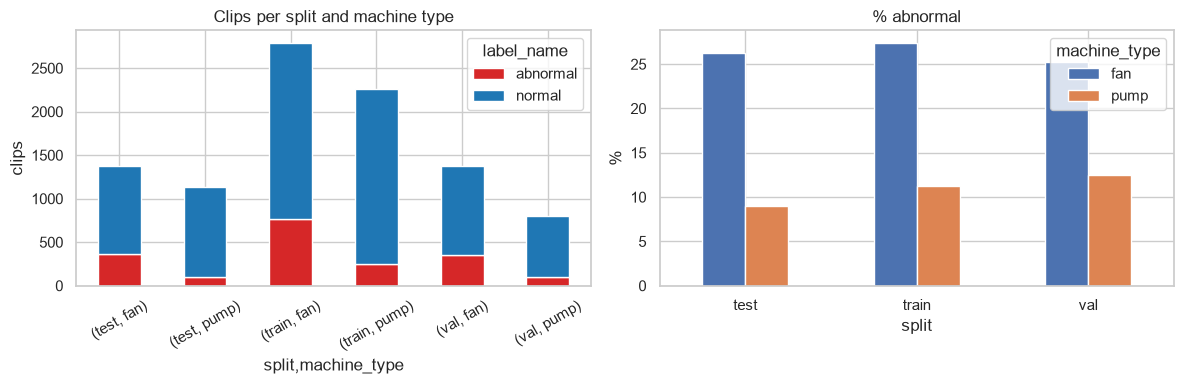

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ct = pd.crosstab([df.split, df.machine_type], df.label_name)
ct.plot(kind="bar", stacked=True, ax=ax[0], color=["#d62728", "#1f77b4"])
ax[0].set_title("Clips per split and machine type"); ax[0].set_ylabel("clips"); ax[0].tick_params(axis="x", rotation=30)
(100 * df.groupby(["split", "machine_type"]).label.mean()).unstack().plot(kind="bar", ax=ax[1])
ax[1].set_title("% abnormal"); ax[1].set_ylabel("%"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); save("q1_class_balance"); plt.show()

## 3. Data integrity (format consistency)

In [4]:
integrity = pd.Series({
    "unreadable files": int((~meta.readable).sum()),
    "sample rates (Hz)": sorted(meta.sample_rate.dropna().astype(int).unique()),
    "channels": sorted(meta.channels.dropna().astype(int).unique()),
    "durations (s)": sorted(meta.duration_s.dropna().round(2).unique())[:5],
    "silent clips (< -60 dB)": int((df.rms_db < -60).sum()),
})
integrity.to_frame("value")

,value
unreadable files,0
sample rates (Hz),[16000]
channels,[8]
durations (s),[10.0]
silent clips (< -60 dB),0


## 4. Look and listen: waveform and log-mel spectrogram
A **log-mel spectrogram** is a picture of sound: time on the x-axis, frequency (on a perceptual mel scale) on the y-axis, colour = loudness in dB. This is the input representation the CNN will use.

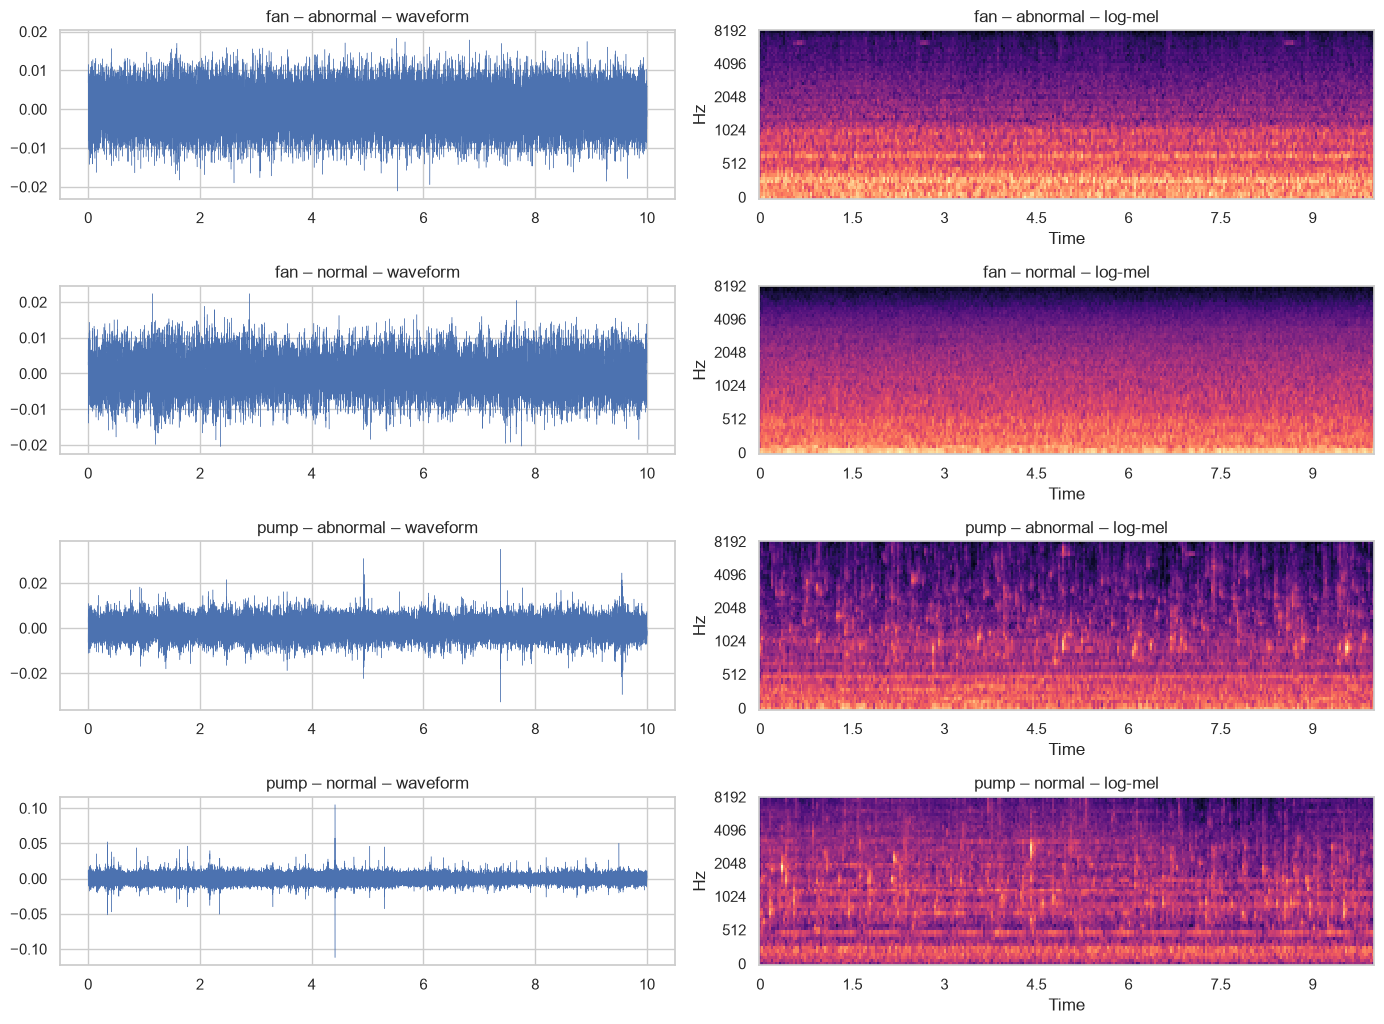

**fan – abnormal**

**fan – normal**

**pump – abnormal**

**pump – normal**

In [5]:
rng = np.random.default_rng(config.SEED)
examples = (dev[dev.split == "train"].groupby(["machine_type", "label_name"])
              .sample(1, random_state=config.SEED).reset_index(drop=True))
fig, axes = plt.subplots(len(examples), 2, figsize=(14, 2.6 * len(examples)))
for i, r in examples.iterrows():
    y = load_audio(config.ROOT / r.path)
    t = np.arange(len(y)) / config.SAMPLE_RATE
    axes[i, 0].plot(t, y, lw=0.3); axes[i, 0].set_title(f"{r.machine_type} – {r.label_name} – waveform")
    S = log_mel(y)
    librosa.display.specshow(S, sr=config.SAMPLE_RATE, hop_length=config.HOP_LENGTH,
                             x_axis="time", y_axis="mel", ax=axes[i, 1])
    axes[i, 1].set_title(f"{r.machine_type} – {r.label_name} – log-mel")
plt.tight_layout(); save("q1_examples_waveform_logmel"); plt.show()

for _, r in examples.iterrows():
    display(Markdown(f"**{r.machine_type} – {r.label_name}**"))
    display(Audio(load_audio(config.ROOT / r.path), rate=config.SAMPLE_RATE))

## 5. Where in frequency do faults show? (train only)
Average log-mel spectrum of normal vs abnormal clips, per machine type, and the difference. Bands with a large difference are where the fault evidence lives.

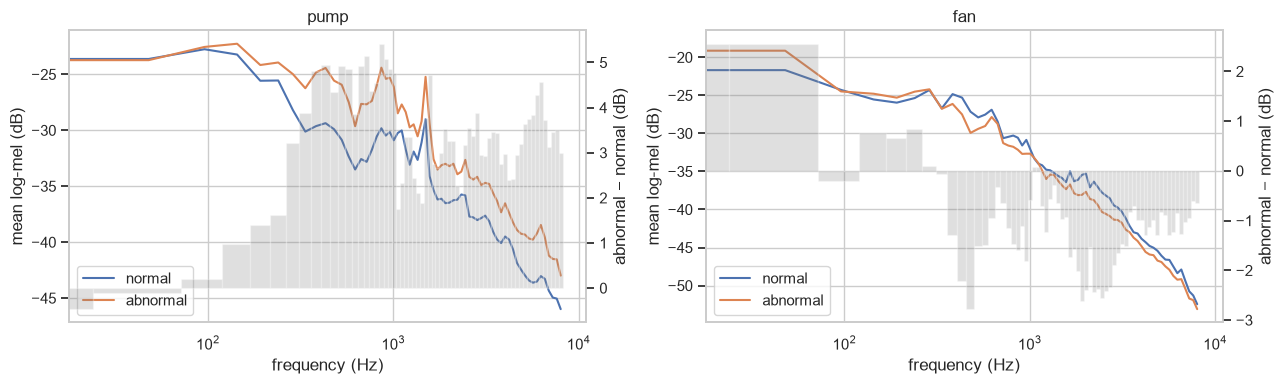

,pump,fan
band 1,431 Hz (+4.9 dB),0 Hz (+2.6 dB)
band 2,670 Hz (+4.9 dB),48 Hz (+2.6 dB)
band 3,718 Hz (+5.1 dB),479 Hz (-2.8 dB)
band 4,862 Hz (+5.4 dB),1911 Hz (-2.6 dB)
band 5,910 Hz (+5.1 dB),2446 Hz (-2.6 dB)


In [6]:
tr = df.split.eq("train").to_numpy()
mel_freqs = librosa.mel_frequencies(n_mels=config.N_MELS, fmax=config.SAMPLE_RATE / 2)
band_report = {}
fig, axes = plt.subplots(1, len(config.MACHINE_TYPES), figsize=(13, 4), squeeze=False)
for ax, m in zip(axes[0], config.MACHINE_TYPES):
    sel = tr & df.machine_type.eq(m).to_numpy()
    n = feats["mel_mean"][sel & (df.label == 0).to_numpy()].mean(0)
    a = feats["mel_mean"][sel & (df.label == 1).to_numpy()].mean(0)
    ax.plot(mel_freqs, n, label="normal"); ax.plot(mel_freqs, a, label="abnormal")
    ax2 = ax.twinx(); ax2.bar(mel_freqs, a - n, width=np.gradient(mel_freqs), alpha=0.25, color="grey")
    ax2.set_ylabel("abnormal − normal (dB)"); ax2.grid(False)
    ax.set_xscale("log"); ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("mean log-mel (dB)")
    ax.set_title(m); ax.legend(loc="lower left")
    top = np.argsort(-np.abs(a - n))[:5]
    band_report[m] = [f"{mel_freqs[k]:.0f} Hz ({a[k]-n[k]:+.1f} dB)" for k in sorted(top)]
plt.tight_layout(); save("q1_mean_spectrum_by_class"); plt.show()
pd.DataFrame(band_report, index=[f"band {i+1}" for i in range(5)])

## 6. Is the fault constant or short events in time? (train only)
For each abnormal clip we measure, frame by frame, how far its spectrum is from the *average normal spectrum of the same machine*. A spiky curve = short transient faults (→ the model must look at local time-frequency patterns, not just a clip average). A flat curve = stationary change.

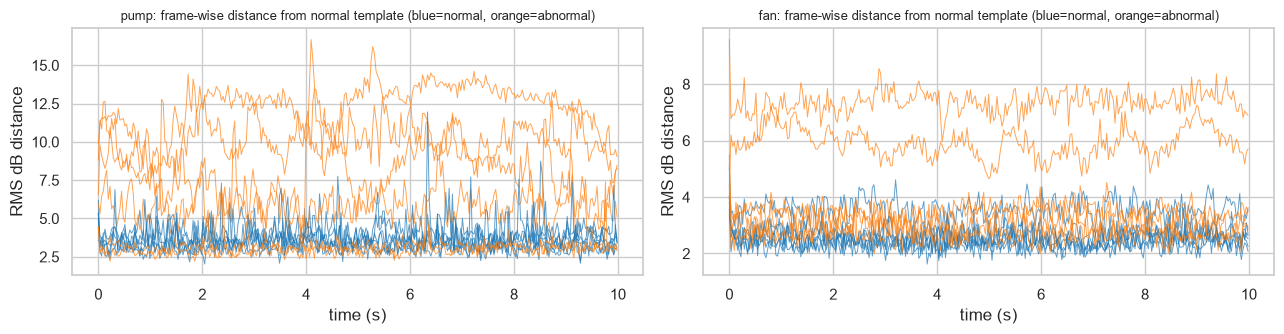

,pump,fan
label,,
normal,2.21,1.47
abnormal,1.56,1.44


In [7]:
def frame_deviation(row, normal_template):
    S = log_mel(load_audio(config.ROOT / row.path))
    return np.sqrt(((S - normal_template[:, None]) ** 2).mean(0))

train = df[df.split == "train"]
fig, axes = plt.subplots(1, len(config.MACHINE_TYPES), figsize=(13, 3.5), squeeze=False)
peakiness = {}
for ax, m in zip(axes[0], config.MACHINE_TYPES):
    vals = []
    for mid in sorted(train[train.machine_type == m].machine_id.unique()):
        g = train[(train.machine_type == m) & (train.machine_id == mid)]
        template = feats["mel_mean"][g[g.label == 0].index].mean(0)
        for lab, colour in [(0, "tab:blue"), (1, "tab:orange")]:
            for _, r in g[g.label == lab].sample(min(3, (g.label == lab).sum()), random_state=config.SEED).iterrows():
                d = frame_deviation(r, template)
                ax.plot(np.arange(len(d)) * config.HOP_LENGTH / config.SAMPLE_RATE, d, color=colour, lw=0.7, alpha=0.7)
                vals.append({"label": lab, "peak_to_median": d.max() / np.median(d)})
    ax.set_title(f"{m}: frame-wise distance from normal template (blue=normal, orange=abnormal)", fontsize=9)
    ax.set_xlabel("time (s)"); ax.set_ylabel("RMS dB distance")
    peakiness[m] = pd.DataFrame(vals).groupby("label").peak_to_median.median()
plt.tight_layout(); save("q1_temporal_deviation"); plt.show()
pd.DataFrame(peakiness).rename(index={0: "normal", 1: "abnormal"}).round(2)

## 7. Machine-to-machine variation vs fault variation (train + validation)
Key question for the split and the architecture: do clips cluster by **machine ID** more strongly than by **normal/abnormal**?

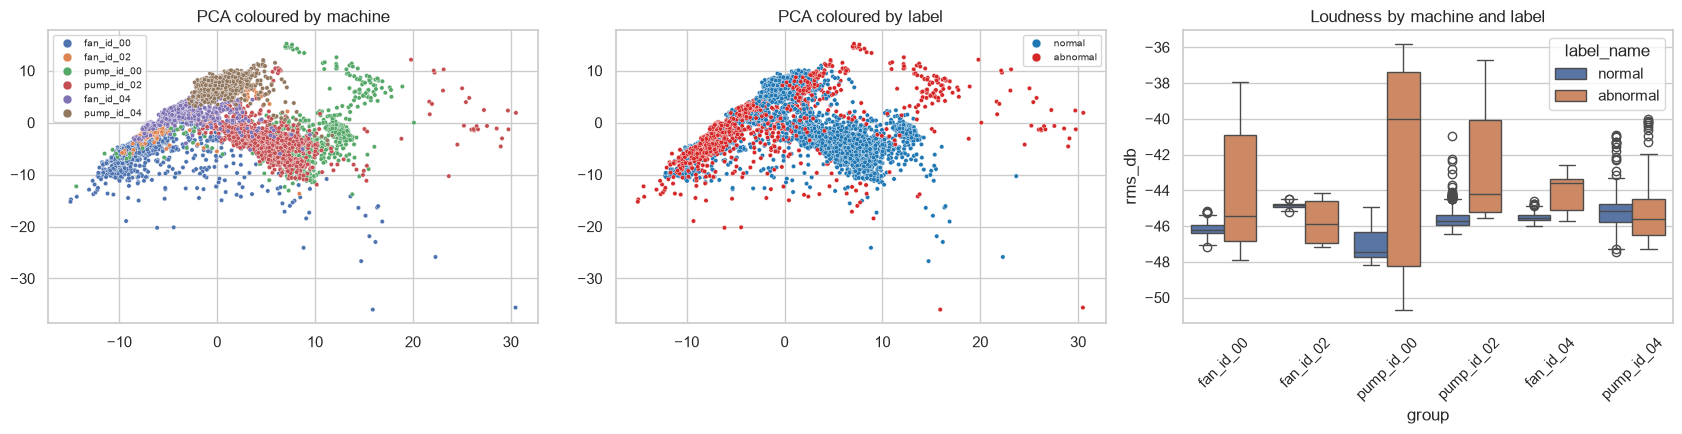

Predict which machine (5-fold accuracy, chance = 0.17): 0.983
Predict normal/abnormal with the SAME features (5-fold ROC-AUC): 0.776
NOTE: this random 5-fold CV mixes clips of the same machine - it is used ONLY to show how strong machine identity is, not as a model result.


In [8]:
idx = dev.index.to_numpy()
X = np.hstack([feats["mel_mean"][idx], feats["mel_std"][idx]])
Z = PCA(2, random_state=config.SEED).fit_transform(StandardScaler().fit_transform(X))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=dev.group.values, s=10, ax=ax[0]); ax[0].set_title("PCA coloured by machine")
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=dev.label_name.values, s=10, ax=ax[1],
                palette={"normal": "tab:blue", "abnormal": "tab:red"}); ax[1].set_title("PCA coloured by label")
sns.boxplot(data=dev, x="group", y="rms_db", hue="label_name", ax=ax[2]); ax[2].tick_params(axis="x", rotation=45)
ax[2].set_title("Loudness by machine and label")
for a in ax[:2]: a.legend(fontsize=7, markerscale=2)
plt.tight_layout(); save("q1_machine_vs_fault_variation"); plt.show()

# Quantify: how easy is it to predict the MACHINE vs the FAULT from the same simple features?
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
acc_machine = cross_val_score(pipe, X, dev.group, cv=5).mean()
auc_fault = cross_val_score(pipe, X, dev.label, cv=5, scoring="roc_auc").mean()
print(f"Predict which machine (5-fold accuracy, chance = {1/dev.group.nunique():.2f}): {acc_machine:.3f}")
print(f"Predict normal/abnormal with the SAME features (5-fold ROC-AUC): {auc_fault:.3f}")
print("NOTE: this random 5-fold CV mixes clips of the same machine - it is used ONLY to show how strong "
      "machine identity is, not as a model result.")

### 7b. Microphone channels — why we use only channel 0

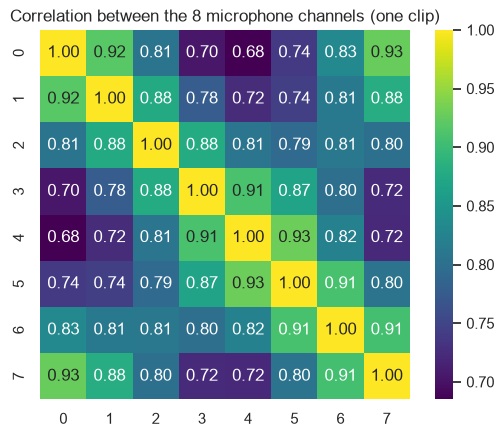

In [9]:
r = dev[dev.split == "train"].iloc[0]
import soundfile as sf
Y, _ = sf.read(config.ROOT / r.path, dtype="float32", always_2d=True)
if Y.shape[1] > 1:
    corr = np.corrcoef(Y.T)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="viridis", square=True)
    plt.title("Correlation between the 8 microphone channels (one clip)"); save("q1_channel_correlation"); plt.show()
else:
    print("mono file")

## 8. Leakage checks and data quality
Generated by `python -m src.leakage_checks` (full report in `reports/leakage_report.md`).

In [10]:
display(Markdown((config.REPORTS_DIR / "leakage_report.md").read_text(encoding="utf-8")))

# Leakage and data-quality report

Clips: 9755 | machines (groups): 8 | SNR: 6_dB

## 1. Group isolation (machine ID)
| split   | machines                                     |
|:--------|:---------------------------------------------|
| test    | fan_id_06, pump_id_06                        |
| train   | fan_id_00, fan_id_02, pump_id_00, pump_id_02 |
| val     | fan_id_04, pump_id_04                        |

Result: PASS - every machine is in exactly one split

## 2. Exact duplicates (hash of decoded audio)
Duplicate sets: 0 | crossing split boundaries: 0

## 3. Near-duplicates across splits
Nearest-neighbour cosine similarity on log-mel summaries:
|       |   within train (clip vs other train clip) |   val/test clip vs nearest train clip |
|:------|------------------------------------------:|--------------------------------------:|
| count |                                 5058      |                             4697      |
| mean  |                                    0.9518 |                                0.5943 |
| std   |                                    0.0483 |                                0.1499 |
| min   |                                    0.5471 |                                0.2094 |
| 25%   |                                    0.9424 |                                0.4841 |
| 50%   |                                    0.9671 |                                0.5885 |
| 75%   |                                    0.9788 |                                0.697  |
| max   |                                    0.9955 |                                0.9732 |

Top-20 most similar cross-split pairs checked on full spectrograms: 0 with correlation > 0.99 (near-duplicates).
Interpretation: if val/test clips are clearly LESS similar to train than train clips are to each other, the group split is doing its job (unseen machines sound different).

## 4. Features available at prediction time
| Column | Allowed as model input? | Reason |
|---|---|---|
| audio waveform (channel 0) | YES | the only thing the engineer uploads / the sensor records |
| label, label_name | NO | this is the target |
| path, folder names (normal/abnormal) | NO | folder name IS the label -> direct leakage |
| machine_id, group | NO | not known for a new machine; would let the model memorise machines |
| split, snr | NO | bookkeeping only |

File names shared by normal and abnormal clips: 407 (file numbering restarts per folder, so the file name alone carries no label - but the folder path does, so the data loader passes ONLY the waveform to the model).

## 5. Shortcut signals / trivial benchmark (fit on train, scored on validation)
| single feature   |   validation ROC-AUC |
|:-----------------|---------------------:|
| rms_db           |                0.796 |

AUC near 0.5 = no shortcut. Clearly above 0.5 = loudness alone separates classes: report it, use it as the trivial benchmark in Q3a, and check the CNN beats it.

## 6. Data quality
- unreadable files: 0
- sample rates: [16000]
- channel counts: [8]
- durations (s): [10.0]
- silent clips (RMS < -60 dB): 0

## 9. Decision consequences: false positives vs false negatives

| Error | What happens on the shop floor | Relative cost |
|---|---|---|
| **False negative** (fault missed) | Machine keeps running with a fault → unplanned breakdown, production stop, possible secondary damage, safety risk | **High** |
| **False positive** (false alarm) | Engineer inspects a healthy machine → ~30–60 min labour, maybe a short stop | Low per event — **but** too many alarms make engineers ignore the system ("alarm fatigue") |

**Consequence for the model:** we want to catch as many faults as possible **while keeping false alarms below a level engineers will tolerate**. So the alarm threshold is set on a fixed false-alarm budget (chosen on the validation set), not at 0.5.
*(Write 3–4 sentences in the report; if you can, cite a maintenance-cost source.)*

## 10. Primary evaluation metric

**Primary: Recall at 5 % false-alarm rate (TPR @ FPR = 0.05)** — *"If the engineer accepts 1 false alarm per 20 healthy checks, what share of real faults do we catch?"*

Why this metric:
1. It maps directly onto the engineer's decision and the cost asymmetry in section 9 (missed faults matter most, but false alarms must be capped).
2. Accuracy is misleading with this class balance (a model that always says "normal" scores the normal-class share shown in section 2).
3. It depends only on how the model **ranks** clips, so the baseline, the CNN and the GenAI model (CLAP) can be compared on the same test clips even though their raw scores are on different scales.

**Secondary:** ROC-AUC (overall ranking quality) and partial AUC for FPR ≤ 0.1 (the low-false-alarm region; standard in the DCASE machine-anomaly challenge).
**Deployment threshold:** chosen on the **validation** machine to give FPR ≈ 5 %; its real FPR on the test machine is reported honestly (it may drift on a new machine).
Implementation: `src/metrics.py` — the same code is used for every model.

## 11. Three findings that constrain the modelling choices
Run all cells above, then **replace the bracketed parts with your own numbers**. Each finding = evidence → consequence for the model.

In [11]:
pct_abn = 100 * df.label.mean()
print(f"[F1 evidence] machine-ID prediction accuracy = {acc_machine:.2f} vs fault ROC-AUC = {auc_fault:.2f}; "
      f"val/test vs train similarity in leakage report section 3")
print(f"[F2 evidence] largest spectral differences: {band_report}")
print(f"[F2 evidence] peak-to-median frame deviation (abnormal vs normal):\n{pd.DataFrame(peakiness).round(2)}")
print(f"[F3 evidence] abnormal share = {pct_abn:.1f}% overall; per split:\n{(100*df.groupby('split').label.mean()).round(1)}")

[F1 evidence] machine-ID prediction accuracy = 0.98 vs fault ROC-AUC = 0.78; val/test vs train similarity in leakage report section 3
[F2 evidence] largest spectral differences: {'pump': ['431 Hz (+4.9 dB)', '670 Hz (+4.9 dB)', '718 Hz (+5.1 dB)', '862 Hz (+5.4 dB)', '910 Hz (+5.1 dB)'], 'fan': ['0 Hz (+2.6 dB)', '48 Hz (+2.6 dB)', '479 Hz (-2.8 dB)', '1911 Hz (-2.6 dB)', '2446 Hz (-2.6 dB)']}
[F2 evidence] peak-to-median frame deviation (abnormal vs normal):
       pump   fan
label            
0      2.21  1.47
1      1.56  1.44
[F3 evidence] abnormal share = 19.8% overall; per split:
split
test     18.4
train    20.2
val      20.5
Name: label, dtype: float64


**Finding 1 – Machine identity dominates the sound.** *[Evidence: PCA clusters by machine; machine predicted with X % accuracy vs fault AUC Y.]*
→ **Consequence:** random file-level splitting would leak machine identity, so we split by machine ID (unseen machine in test). The model must generalise across machines, which favours a **pretrained audio backbone** (transfer learning) plus per-clip normalisation and noise augmentation, and we expect a drop from validation to test.

**Finding 2 – Fault evidence is localised in specific frequency bands [list bands] and [is / is not] short in time [peak-to-median ratio].**
→ **Consequence:** clip-averaged features (the MFCC-mean baseline) can blur short, band-limited events; a **2-D CNN on the log-mel spectrogram** keeps the time-frequency structure. This also motivates Grad-CAM for XAI (it highlights time-frequency regions the engineer can listen to).

**Finding 3 – Classes are imbalanced ([X] % abnormal) and the recordings contain factory background noise.**
→ **Consequence:** accuracy is not usable; we use recall at 5 % FPR, class-weighted loss (or balanced sampling), threshold selection on validation only, and noise / SNR robustness tests (e.g. −6 dB clips as out-of-distribution inputs in the web app, Q4).